# Hurst Regimes 01 — does $H$ vary, persist, and move the terminal move?

**Discussion:** `discussions/Hurst_Regimes/001_claude_branch_preregistration.md` · **Code:** `src/data_engineering/modeling/hurst_regimes.py`

These are the three prerequisites for an HMM on the Hurst exponent. Each session is the 288 five-minute bars to the 08:00 UTC expiry. Returns are deseasonalized by a development-only intraday clock.

- $H_d$ is the change-of-frequency estimate (Ivan's thesis §5.1) on the session path.
- $VR_d = (\sum r)^2/\sum r^2$ is the terminal move per unit of path variance.

Null: fractional Gaussian noise at a constant $H_0$, multiplied by each block's own volatility path. This keeps clustering and bursts and removes any variation in $H$.

| Gate | Statistic | Passes when (Holm across assets, ≥ half of eligible assets, plus size) |
|---|---|---|
| G1 variation | $\operatorname{Var}(H_d)$ vs null | excess SD ≥ 0.02 |
| G2 persistence | Spearman $(H_d, H_{d+1})$ vs null | excess ρ ≥ 0.10 |
| G3 relevance | Spearman $(H_d, \log VR_{d+1})$ vs null | excess ρ > 0 |

Development: sessions ≤ 2026-03-31. Confirmation (G3 only, run once): sessions ≥ 2026-04-01, enabled with `HR_CONFIRM=1` **only after Ivan accepts the development readout**.

Environment (optional): `HR_HISTORY_DIR` (default `DERIBIT_DATA_ROOT/history/price_5m`), `HR_ASSETS`, `HR_N_REP`.

In [1]:
from pathlib import Path
import json, os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 60)
load_dotenv()
DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    raise RuntimeError('Repository root not found.')
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from data_engineering.modeling import hurst_regimes as hr

HIST_DIR = Path(os.getenv('HR_HISTORY_DIR', str(DATA_ROOT / 'history' / 'price_5m')))
ASSETS = [x.strip().upper() for x in os.getenv('HR_ASSETS', 'AVAX,BTC,ETH,HYPE,SOL,TRX,XRP').split(',') if x.strip()]
N_REP = int(os.getenv('HR_N_REP', str(hr.N_REP)))
CONFIRM = os.getenv('HR_CONFIRM', '').strip() == '1'
OUT = PROJECT_ROOT / 'notebooks' / 'Hurst_Regimes' / '01'
OUT.mkdir(parents=True, exist_ok=True)
print('Hurst Regimes 01', hr.VERSION, hr.selftest())
print(json.dumps(hr.registration(), indent=2))
if CONFIRM and not (OUT / '01_decision_development.json').exists():
    raise RuntimeError('Confirmation requires a committed development readout first.')

Hurst Regimes 01 0.1.0 {'version': '0.1.0', 'const_p1': 0.869, 'regime_p1': 0.016, 'regime_rho2': 0.656, 'regime_rho3': 0.567, 'ok': True}
{
  "version": "0.1.0",
  "bars": 288,
  "min_bars": 280,
  "min_blocks": 200,
  "conf_min_blocks": 100,
  "dev_end": "2026-03-31",
  "conf_start": "2026-04-01",
  "n_rep": 400,
  "seed": 9001,
  "vol_win": 12,
  "g1_min_excess_sd": 0.02,
  "g2_min_excess_rho": 0.1,
  "alpha_holm": 0.05,
  "verdict_rule": "PROCEED_TO_HMM iff G1,G2,G3 pass on development and G3 passes on confirmation"
}


## 1. Session blocks

In [2]:
hist = hr.load_history(HIST_DIR, ASSETS)
print(hist.groupby('underlying').agg(first=('state_time', 'min'), last=('state_time', 'max'), n=('close', 'size'),
                                     source=('source', lambda s: ','.join(sorted(set(map(str, s)))))))
blocks = {}
for a in sorted(hist.underlying.unique()):
    s, R = hr.session_blocks(hist, a)
    dev = s <= hr.DEV_END
    conf = s >= hr.CONF_START
    clock = hr.clock_profile(R[dev & (np.isfinite(R).sum(1) >= hr.MIN_BARS)])
    blocks[a] = dict(s=s, R=R, dev=dev, conf=conf, clock=clock)
    ok = np.isfinite(R).sum(1) >= hr.MIN_BARS
    print(f'{a}: sessions {len(s)} | valid dev {int((ok & dev).sum())} | valid conf {int((ok & conf).sum())}')

                               first                      last       n        source
underlying                                                                          
AVAX       2024-09-01 00:05:00+00:00 2026-10-11 00:05:00+00:00  221761  binance_spot
BTC        2024-09-01 00:05:00+00:00 2026-10-11 00:05:00+00:00  221761  binance_spot
ETH        2024-09-01 00:05:00+00:00 2026-10-11 00:05:00+00:00  221761  binance_spot
HYPE       2026-09-24 11:05:00+00:00 2026-10-11 00:05:00+00:00    4765  binance_spot
SOL        2024-09-01 00:05:00+00:00 2026-10-11 00:05:00+00:00  221761  binance_spot
TRX        2024-09-01 00:05:00+00:00 2026-10-11 00:05:00+00:00  221761  binance_spot
XRP        2024-09-01 00:05:00+00:00 2026-10-11 00:05:00+00:00  221761  binance_spot
AVAX: sessions 771 | valid dev 576 | valid conf 193
BTC: sessions 771 | valid dev 576 | valid conf 193
ETH: sessions 771 | valid dev 576 | valid conf 193
HYPE: sessions 17 | valid dev 0 | valid conf 15
SOL: sessions 771 | valid dev 576

## 2. Development gates

In [3]:
rows, block_tabs = [], []
t0 = time.time()
for a, b in blocks.items():
    if (np.isfinite(b['R'][b['dev']]).sum(1) >= hr.MIN_BARS).sum() < 30:
        print(f'{a}: too few development blocks, skipped'); continue
    o = hr.asset_gates(b['s'][b['dev']], b['R'][b['dev']], b['clock'], n_rep=N_REP, seed=hr.SEED)
    block_tabs.append(o.pop('blocks').assign(underlying=a, window='development'))
    rows.append({'underlying': a, **o})
    print(f'{a}: done ({time.time() - t0:.0f}s)')
dev_table = pd.DataFrame(rows)
dev_decision = hr.decide(dev_table)
cols = ['underlying', 'n_blocks', 'H_mean', 'H_sd', 'null_H_sd', 'excess_sd', 'p1', 'rho2', 'rho2_null', 'p2',
        'rho3', 'rho3_null', 'p3', 'vr_next_low', 'vr_next_mid', 'vr_next_high', 'H10_mean']
display(dev_table[cols].round(4))
print(json.dumps(dev_decision, indent=2))

AVAX: done (5s)
BTC: done (10s)
ETH: done (15s)
HYPE: too few development blocks, skipped
SOL: done (20s)
TRX: done (25s)
XRP: done (30s)


,underlying,n_blocks,H_mean,H_sd,null_H_sd,excess_sd,p1,rho2,rho2_null,p2,rho3,rho3_null,p3,vr_next_low,vr_next_mid,vr_next_high,H10_mean
0,AVAX,576,0.5010,0.1089,0.1053,0.0276,0.1446,0.1870,-0.0041,0.0025,-0.0263,0.0009,0.7357,0.9520,0.9780,0.8747,0.4819
1,BTC,576,0.5060,0.1086,0.1093,0.0000,0.5786,0.0970,-0.0015,0.0075,0.0077,0.0036,0.4613,0.6607,0.8690,0.6860,0.4823
2,ETH,576,0.5049,0.1116,0.1120,0.0000,0.5387,0.0954,-0.0042,0.0050,-0.0276,0.0033,0.7681,0.7577,0.9299,0.6292,0.4919
3,SOL,576,0.5091,0.1077,0.1053,0.0224,0.2394,0.0465,-0.0038,0.1197,-0.0960,0.0014,0.9900,0.8670,0.8971,0.7844,0.4903
4,TRX,576,0.4480,0.1293,0.1073,0.0721,0.0025,0.3915,-0.0005,0.0025,0.0327,0.0022,0.2344,1.0595,1.0612,1.0591,0.4841
5,XRP,576,0.5109,0.1101,0.1101,0.0033,0.4938,0.1179,-0.0019,0.0025,-0.0007,0.0011,0.5436,0.7462,0.6773,0.8832,0.4819


{
  "eligible_assets": 6,
  "G1_assets_passing": 1,
  "G1": false,
  "G2_assets_passing": 5,
  "G2": true,
  "G3_assets_passing": 0,
  "G3": false,
  "median_excess_sd": 0.012827804724312043,
  "median_excess_rho2": 0.10973128733274626,
  "median_excess_rho3": -0.014471359860267968,
  "development_all_pass": false
}


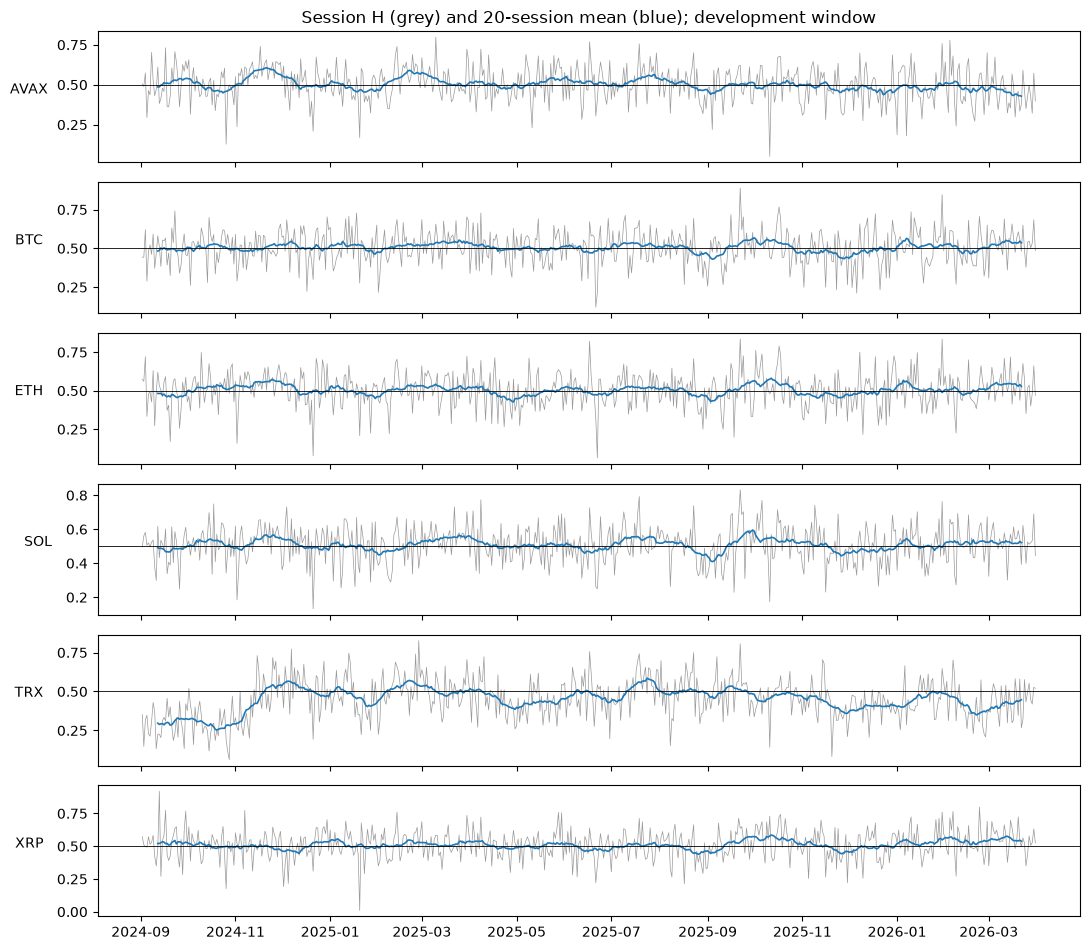

In [4]:
bt = pd.concat(block_tabs, ignore_index=True)
fig, axes = plt.subplots(len(dev_table), 1, figsize=(11, 1.6 * len(dev_table)), sharex=True)
axes = np.atleast_1d(axes)
for ax, (a, g) in zip(axes, bt.groupby('underlying')):
    x = pd.to_datetime(g.session)
    ax.plot(x, g.H, lw=0.5, color='0.6'); ax.plot(x, g.H.rolling(20, center=True).mean(), lw=1.2, color='C0')
    ax.axhline(0.5, color='k', lw=0.6); ax.set_ylabel(a, rotation=0, labelpad=20)
axes[0].set_title('Session H (grey) and 20-session mean (blue); development window')
plt.tight_layout(); plt.show()

## 3. Confirmation (G3, run once, only with `HR_CONFIRM=1`)

In [5]:
conf_decision, conf_table = None, None
if CONFIRM:
    rows = []
    for a in dev_table.underlying:
        b = blocks[a]
        H0 = float(dev_table.loc[dev_table.underlying == a, 'H0'].iloc[0])
        o = hr.asset_gates(b['s'][b['conf']], b['R'][b['conf']], b['clock'], n_rep=N_REP, seed=hr.SEED + 1, H0=H0)
        block_tabs.append(o.pop('blocks').assign(underlying=a, window='confirmation'))
        rows.append({'underlying': a, **o})
    conf_table = pd.DataFrame(rows)
    conf_decision = hr.decide(conf_table, min_blocks=hr.CONF_MIN_BLOCKS)
    display(conf_table[cols].round(4))
    print(json.dumps(conf_decision, indent=2))
else:
    print('Confirmation not run (HR_CONFIRM != 1).')

Confirmation not run (HR_CONFIRM != 1).


## 4. Verdict and outputs

In [6]:
if not dev_decision.get('development_all_pass'):
    verdict = 'STOP'
elif conf_decision is None:
    verdict = 'PENDING_CONFIRMATION'
else:
    verdict = 'PROCEED_TO_HMM' if conf_decision['G3'] else 'STOP'
print('BRANCH VERDICT:', verdict)
dev_table.to_csv(OUT / '01_asset_gates_development.csv', index=False, float_format='%.6g')
pd.concat(block_tabs, ignore_index=True).to_csv(OUT / '01_session_H.csv.gz', index=False, float_format='%.5g', compression='gzip')
(OUT / '01_decision_development.json').write_text(json.dumps({'development': dev_decision, 'registration': hr.registration()}, indent=2))
if conf_table is not None:
    conf_table.to_csv(OUT / '01_asset_gates_confirmation.csv', index=False, float_format='%.6g')
    (OUT / '01_decision_confirmation.json').write_text(json.dumps({'confirmation': conf_decision, 'verdict': verdict}, indent=2))
meta = {'module': '01_hurst_variation_gates', 'version': hr.VERSION, 'history_dir': str(HIST_DIR), 'assets': list(dev_table.underlying),
        'n_rep': N_REP, 'confirm_run': CONFIRM, 'verdict': verdict,
        'sources': sorted(set(map(str, hist['source'].dropna().unique()))) if 'source' in hist else []}
(OUT / '01_run_metadata.json').write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=2))

BRANCH VERDICT: STOP
{
  "module": "01_hurst_variation_gates",
  "version": "0.1.0",
  "history_dir": "D:\\MarketData\\Deribit\\history\\price_5m",
  "assets": [
    "AVAX",
    "BTC",
    "ETH",
    "SOL",
    "TRX",
    "XRP"
  ],
  "n_rep": 400,
  "confirm_run": false,
  "verdict": "STOP",
  "sources": [
    "binance_spot"
  ]
}
